# k-means clustering notebook
Run notebooks in the following order:\
`preprocessing.ipynb -> imputation.R -> dimensionality_reduction.R -> kmeans_clustering.ipynb`

In [1]:
# Update path and working directory with project root
import os
import sys
from pathlib import Path

project_path = next(path for path in [Path(os.getcwd()), *Path(os.getcwd()).parents] if path.stem == "esa_consulting")
os.chdir(project_path)
sys.path.insert(0, str(project_path))

In [2]:
# Imports
from pathlib import Path
from typing import cast

import numpy as np
import pandas as pd
import plotnine as p9
from gapstat import gapstat_score
from IPython.display import display
from scipy.stats import chi2_contingency
from sklearn import clone
from sklearn.cluster import KMeans

from utils.bootstrap_utils import bootstrap, bootstrap_grid_search
from utils.clustering_utils import (
    cluster_summaries,
    predict_clustering_labels,
    predict_clustering_proba,
    print_clustering_info,
)
from utils.metrics_utils import (
    adjusted_rand_score,
    association,
    calinski_harabasz_score,
    davies_bouldin_score,
    dunn_index,
    normalized_mutual_info_score,
    silhouette_score,
    variation_of_information,
)
from utils.misc_utils import contingency_matrix, std_weighted, turn_cats_to_continuous
from utils.plotting_utils import make_plot_mixture_weights, theme_ggplot
from utils.saving_utils import DatasetBundle, save_plot

pd.options.mode.copy_on_write = True
pd.options.future.infer_string = True

In [3]:
# Load data
data_discov_full = DatasetBundle.load(Path("data/preprocessed/data_discov_full"))
data_discov_full.meta = cast(pd.DataFrame, data_discov_full.meta)
data_discov_full.na = cast(pd.DataFrame, data_discov_full.na)
data_valid_full = DatasetBundle.load(Path("data/preprocessed/data_valid_full"))
data_valid_full.meta = cast(pd.DataFrame, data_valid_full.meta)
data_valid_full.na = cast(pd.DataFrame, data_valid_full.na)

data_discov_mfa = pd.read_parquet(Path("data/dim_red/data_discov_mfa.parquet"))
data_valid_mfa = pd.read_parquet(Path("data/dim_red/data_valid_mfa.parquet"))

# Set outputs folder
outputs_folder = "outputs/kmeans_clustering"

# Set sample weights
sample_weight_discov = data_discov_full.data["wichtn"].to_numpy()
sample_weight_valid = data_valid_full.data["wichtn"].to_numpy()

In [4]:
# Create RNG for reproducibility
rng = np.random.default_rng(352532)
rng1, rng2, rng3 = rng.spawn(3)
kmeans_discov = KMeans(random_state=np.random.RandomState(rng1.bit_generator))
kmeans_valid = KMeans(random_state=np.random.RandomState(rng2.bit_generator))

n_boot = 10
param_grid = {"n_clusters": range(2, 51)}
within_metrics = (
    lambda e, X, sample_weight: e.score(X, sample_weight=sample_weight),
    lambda e, X, sample_weight: davies_bouldin_score(X, labels=e.predict(X), sample_weight=sample_weight),
    lambda e, X, sample_weight: calinski_harabasz_score(X, labels=e.predict(X), sample_weight=sample_weight),
    lambda e, X, sample_weight: silhouette_score(X, labels=e.predict(X), sample_weight=sample_weight),
    lambda e, X, sample_weight: dunn_index(X, labels=e.predict(X)),
)
between_metrics = (
    lambda x, y, sample_weight: adjusted_rand_score(x, y, sample_weight=sample_weight),
    lambda x, y, sample_weight: normalized_mutual_info_score(x, y, sample_weight=sample_weight),
    lambda x, y, sample_weight: variation_of_information(x, y, sample_weight=sample_weight),
    lambda x, y, sample_weight: association(contingency_matrix(x, y, sample_weight=sample_weight), correction=False),
    lambda x, y, sample_weight: (
        chi2_contingency(contingency_matrix(x, y, sample_weight=sample_weight), correction=False).statistic
    ),
)
within_metric_names = {i: name for i, name in enumerate(["neg_sum_of_sq", "dbi", "chi", "si", "di"])}
between_metric_names = {i: name for i, name in enumerate(["ari", "nmi", "vi", "assoc", "chi2"])}

within_results_discov, between_results_discov = bootstrap_grid_search(
    kmeans_discov,
    data_discov_mfa.to_numpy(),
    param_grid,
    n_boot=n_boot,
    within_metrics=within_metrics,
    between_metrics=between_metrics,
    sample_weight=sample_weight_discov,
    rng=rng3,
)

within_results_discov["metric"] = within_results_discov["metric"].cat.rename_categories(within_metric_names)
between_results_discov["metric"] = between_results_discov["metric"].cat.rename_categories(between_metric_names)
metrics_results_discov = pd.concat([within_results_discov, between_results_discov], ignore_index=True)

49/49


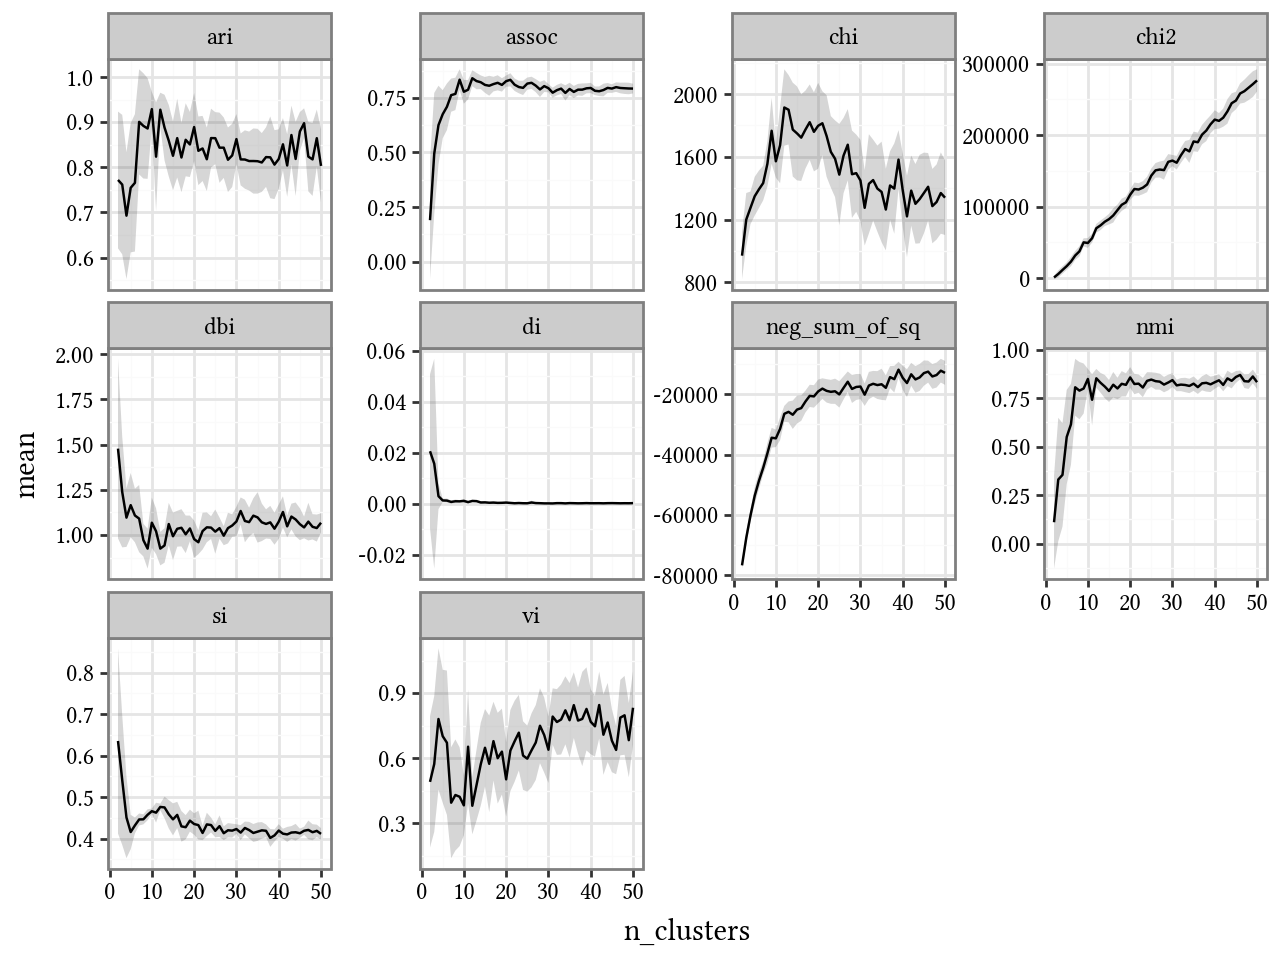

In [10]:
# Plot all metrics
(
    p9.ggplot(metrics_results_discov)
    + p9.aes(x="n_clusters", y="mean")
    + p9.geom_ribbon(p9.aes(ymin="mean - std", ymax="mean + std"), alpha=0.2)
    + p9.geom_line()
    + p9.facet_wrap("metric", scales="free_y")
    + theme_ggplot
)

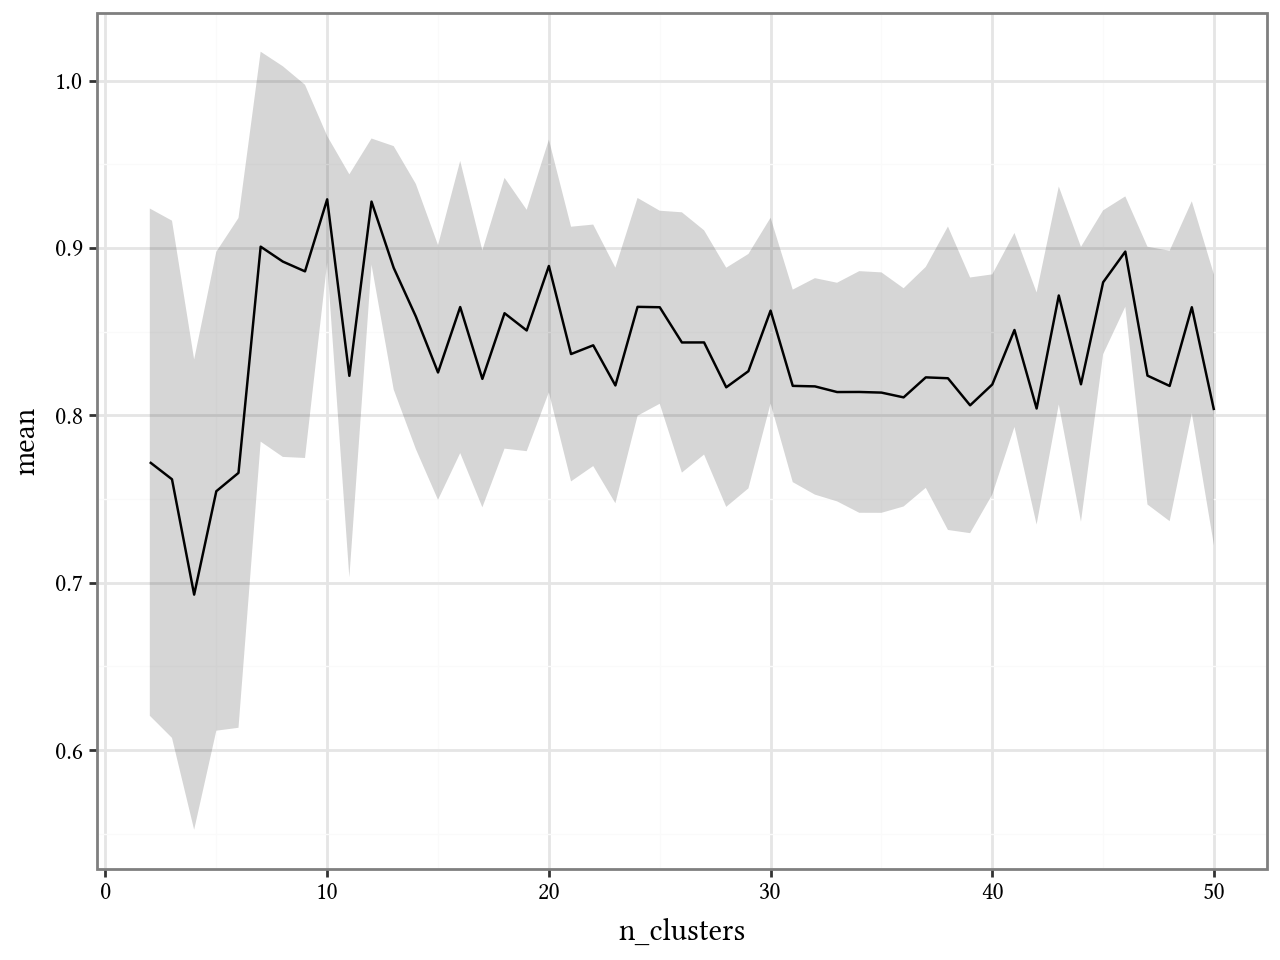

In [32]:
# Plot a single metric
metric = "ari"
(
    p9.ggplot(metrics_results_discov[lambda x: x["metric"].eq(metric)])
    + p9.aes(x="n_clusters", y="mean")
    + p9.geom_ribbon(p9.aes(ymin="mean - std", ymax="mean + std"), alpha=0.2)
    + p9.geom_line()
    + theme_ggplot
)

In [19]:
# Find best performing parameters
smaller_is_better_metrics = ["dbi", "vi"]
bigger_is_better_metrics = ["neg_sum_of_sq", "chi", "si", "di", "ari", "nmi", "vi", "assoc", "chi2"]
min_metrics = metrics_results_discov.loc[lambda x: x["metric"].isin(smaller_is_better_metrics)].loc[
    lambda x: x.groupby("metric")["mean"].idxmin()
]
max_metrics = metrics_results_discov.loc[lambda x: x["metric"].isin(bigger_is_better_metrics)].loc[
    lambda x: x.groupby("metric")["mean"].idxmax()
]
best_metrics = pd.concat([min_metrics, max_metrics])
print("minimum mean values:")
display(min_metrics)
print("maximum mean values:")
display(max_metrics)

minimum mean values:


,metric,mean,std,n_clusters
36,dbi,0.924186,0.110343,9
297,vi,0.381048,0.131474,12


maximum mean values:


,metric,mean,std,n_clusters
285,ari,0.929170,0.037857,10
298,assoc,0.839675,0.036333,12
52,chi,1914.096345,243.581638,12
489,chi2,276590.707690,15504.575290,50
4,di,0.020585,0.030202,2
185,neg_sum_of_sq,-11832.503499,2622.588304,39
466,nmi,0.870090,0.023106,46
3,si,0.635279,0.222986,2
447,vi,0.845637,0.154217,42


In [ ]:
# Set best parameters and refit models
selection_metric = "ari"
best_params = (
    best_metrics[lambda x: x["metric"].eq(selection_metric)]
    .drop(columns=["metric", "mean", "std"])
    .to_dict(orient="records")[0]
)
print(f"Best parameters wrt. {selection_metric}: {best_params}")

kmeans_discov.set_params(**best_params)
kmeans_valid.set_params(**best_params)
model_discov = clone(kmeans_discov)
model_valid = clone(kmeans_valid)
model_discov.fit(data_discov_mfa, sample_weight=sample_weight_discov)
model_valid.fit(data_valid_mfa, sample_weight=sample_weight_valid)
None

Best parameters wrt. neg_sum_of_sq: {'n_clusters': 39}


In [25]:
# Apply models to predict labels
labels_discov = predict_clustering_labels(model_discov, data_discov_mfa)
labels_valid = predict_clustering_labels(model_valid, data_valid_mfa)


# Save predictions
pd.DataFrame({"label": labels_discov}).to_parquet(Path(outputs_folder, "cluster_pred_discov.parquet"), index=False)
pd.DataFrame({"label": labels_valid}).to_parquet(Path(outputs_folder, "cluster_pred_valid.parquet"), index=False)

### Get cluster summaries

In [27]:
treat_cat_as_continuous = data_discov_full.meta.loc[lambda x: x["type"].isin(["binary", "ordinal"]), "name"]
data_discov_cont = turn_cats_to_continuous(data_discov_full.data, treat_cat_as_continuous).select_dtypes(
    exclude="category"
)
data_valid_cont = turn_cats_to_continuous(data_valid_full.data, treat_cat_as_continuous).select_dtypes(
    exclude="category"
)

In [28]:
# Interpretation of continuous, binary, and ordinal variables
cluster_discov_summaries = cluster_summaries(data_discov_cont, labels_discov, sample_weight=sample_weight_discov)
cluster_discov_summaries

,zeit_mean,zeit_std,wichtn_mean,wichtn_std,ges_mean,ges_std,alter_mean,alter_std,altq_mean,altq_std,...,schm_kat_mean,schm_kat_std,schl_kat_mean,schl_kat_std,ber_kat_mean,ber_kat_std,depr_kat_mean,depr_kat_std,neur_kat_mean,neur_kat_std
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.0,0.0,1.758193,1.396931,0.600324,0.489832,40.435318,12.749659,3.429013,1.553444,...,0.464486,0.677566,0.003396,5.817373e-02,0.002541,0.050344,0.000000,0.000000,0.000000,0.000000
1,0.0,0.0,1.247372,1.025613,0.330226,0.470294,38.066189,13.440252,3.068414,1.696142,...,0.725033,0.753329,0.015516,1.270205e-01,0.010211,0.100534,0.030611,0.293641,0.000000,0.000000
2,0.0,0.0,1.792067,0.000000,0.000000,0.000000,32.000000,0.000000,3.000000,0.000000,...,2.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.0,0.0,1.952786,1.532497,0.261722,0.439572,35.385153,11.483864,2.847430,1.527648,...,0.809393,0.857874,0.050101,2.868569e-01,0.024534,0.185984,0.041422,0.311540,0.018039,0.231930
4,0.0,0.0,2.292185,1.456552,0.581809,0.493262,50.523056,8.281028,4.578396,0.991495,...,2.043937,1.331468,1.925287,1.408120e+00,1.850386,1.458503,1.634175,1.493987,0.767600,1.309042
5,0.0,0.0,1.158377,0.521235,0.259935,0.438599,24.125299,2.721152,1.326542,0.468948,...,0.712938,0.851192,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,0.0,0.0,1.843489,1.639338,0.357362,0.479223,36.129391,12.783875,2.830175,1.684835,...,0.954330,0.739399,0.047085,2.391002e-01,0.027617,0.163872,0.426993,1.041292,0.021988,0.146644
7,0.0,0.0,2.312819,1.690200,0.412872,0.492350,43.048903,11.255848,3.730475,1.278726,...,1.011655,0.947685,0.095067,3.957354e-01,0.013626,0.115933,0.170675,0.684428,0.000000,0.000000
8,0.0,0.0,1.733331,1.066098,0.542849,0.498161,36.098507,10.721527,3.073001,1.370466,...,1.252697,0.866659,0.260498,8.071248e-01,0.031093,0.173568,0.000000,0.000000,0.000000,0.000000


In [29]:
# Interpretation of continuous, binary, and ordinal variables
cluster_valid_summaries = cluster_summaries(data_valid_cont, labels_valid, sample_weight=sample_weight_valid)
cluster_valid_summaries

,zeit_mean,zeit_std,wichtn_mean,wichtn_std,ges_mean,ges_std,alter_mean,alter_std,altq_mean,altq_std,...,schm_kat_mean,schm_kat_std,schl_kat_mean,schl_kat_std,ber_kat_mean,ber_kat_std,depr_kat_mean,depr_kat_std,neur_kat_mean,neur_kat_std
cluster,,,,,,,,,,,,,,,,,,,,,
0,1.0,0.0,1.847332,1.529441e+00,0.510644,0.499887,44.199126,12.964558,3.825611,1.615676,...,1.638902,0.926465,0.940557,1.046979,0.748581,0.979129,1.065575,1.386407,0.200511,0.688127
1,1.0,0.0,1.288447,9.968071e-01,0.369877,0.482771,38.420424,12.482759,3.212861,1.545869,...,0.850339,0.687350,0.006719,0.106149,0.005540,0.074224,0.003784,0.086906,0.000000,0.000000
2,1.0,0.0,1.734343,1.590934e+00,0.485253,0.499782,45.200563,12.684436,4.004870,1.472443,...,0.163314,0.533755,0.017053,0.167400,0.005883,0.113476,0.061693,0.423468,0.018559,0.235229
3,1.0,0.0,2.793923,0.000000e+00,0.000000,0.000000,52.000000,0.000000,5.000000,0.000000,...,3.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,1.0,0.0,2.219237,1.424125e+00,0.647584,0.477723,34.064120,8.363522,2.788899,1.063988,...,1.016430,0.808971,0.000000,0.000000,0.000000,0.000000,0.371506,0.988181,0.480117,1.099927
5,1.0,0.0,2.388287,1.694570e+00,0.500803,0.499999,46.038652,9.966953,4.039492,1.149911,...,1.722734,0.957030,0.373126,0.844584,0.213990,0.741921,1.094812,1.434967,0.176329,0.705617
6,1.0,0.0,2.031677,1.786972e+00,0.347756,0.476258,42.411700,13.020008,3.696358,1.544813,...,0.259611,0.644200,0.012581,0.126133,0.000000,0.000000,0.021559,0.253404,0.006221,0.136474
7,1.0,0.0,1.327874,9.244216e-01,0.257451,0.437230,31.766826,7.497074,2.564111,1.214054,...,0.709740,0.827241,0.073646,0.376654,0.012862,0.112680,0.000000,0.000000,0.000000,0.000000
8,1.0,0.0,4.026628,2.543616e+00,0.260500,0.438908,38.445487,10.482748,3.382467,1.256815,...,1.280051,0.965888,0.069854,0.367189,0.000000,0.000000,1.462581,1.499533,0.069854,0.367189


### Compare clusterings
We are dealing with _inferential clustering_, because we are clustering individuals and not variables.\
Method-based validation: The same clustering method is applied to the validation data, and the results are compared between clusterings.\
Result-based validation: The trained cluster algorithm is applied to the validation data, and the results are compared between datasets.\
Cluster stability: The results from the trained and transferred clusterings from the method- and result-based validation steps are compared.

In [ ]:
# Compare clusterings
within_results_valid, between_results_valid = bootstrap(
    kmeans_valid,
    data_valid_mfa,
    n_boot=n_boot,
    within_metrics=within_metrics,
    between_metrics=between_metrics,
    sample_weight=sample_weight_valid,
    rng=np.random.default_rng(2352),
)

within_results_valid["metric"] = within_results_valid["metric"].cat.rename_categories(within_metric_names)
between_results_valid["metric"] = between_results_valid["metric"].cat.rename_categories(between_metric_names)
metrics_results_valid = pd.concat([within_results_valid, between_results_valid], ignore_index=True)

mask = np.logical_and.reduce([metrics_results_discov[col] == val for col, val in best_params.items()])
cluster_comparison = (
    metrics_results_discov[mask]
    .drop(columns=best_params)
    .set_index("metric")
    .join(metrics_results_valid.set_index("metric"), lsuffix="_discov", rsuffix="_valid")
    .reset_index()
)
cluster_comparison